<a href="https://colab.research.google.com/github/Zeinab-Sabry/breast-cancer-classification/blob/main/breast_cancer_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

# 1) Dataset Exploration
### 1.1 Structure, Dimensions, Column Names, and Data Types

In [ ]:
cols = ["Sample_code_number", "Clump_thickness", "Uniformity_of_cell_size",
        "Uniformity_of_cell_shape", "Marginal_adhesion",
        "Single_epithelial_cell_size", "Bare_nuclei", "Bland_chromatin",
        "Normal_nucleoli", "Mitoses", "Class"]

data = pd.read_csv("breast-cancer-wisconsin.data", header=None,
                   names=cols, na_values="?")
data.to_csv("breast_cancer_wisconsin.csv", index=False)
RANDOM_STATE = 42

print("shape:", data.shape)
print("\nData types:")
print(data.dtypes)
print("\nConcise summary:")
data.info()

shape: (699, 11)

Data types:
Sample_code_number               int64
Clump_thickness                  int64
Uniformity_of_cell_size          int64
Uniformity_of_cell_shape         int64
Marginal_adhesion                int64
Single_epithelial_cell_size      int64
Bare_nuclei                    float64
Bland_chromatin                  int64
Normal_nucleoli                  int64
Mitoses                          int64
Class                            int64
dtype: object

Concise summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Sample_code_number           699 non-null    int64  
 1   Clump_thickness              699 non-null    int64  
 2   Uniformity_of_cell_size      699 non-null    int64  
 3   Uniformity_of_cell_shape     699 non-null    int64  
 4   Marginal_adhesion            699 non-null    int64 

In [ ]:
print("Random 5 rows:")
display(data.sample(5, random_state=RANDOM_STATE))

Random 5 rows:


,Sample_code_number,Clump_thickness,Uniformity_of_cell_size,Uniformity_of_cell_shape,Marginal_adhesion,Single_epithelial_cell_size,Bare_nuclei,Bland_chromatin,Normal_nucleoli,Mitoses,Class
158,1193683,1,1,2,1,3,NaN,1,1,1,2
499,1217952,4,1,1,1,2,1.0,2,1,1,2
396,1176187,3,1,1,1,2,1.0,3,1,1,2
155,1192325,5,5,5,6,3,10.0,3,1,1,4
321,733639,3,1,1,1,2,NaN,3,1,1,2


### 1.2 Target Variable, Features, and Feature Meanings

In [ ]:
target_col = "Class"
id_col = "Sample_code_number"
feature_cols = [c for c in data.columns if c not in (id_col, target_col)]

print("Target variable  :", target_col)
print("Identifier column:", id_col)
print(f"Features ({len(feature_cols)}):")
for f in feature_cols:
    print("  -", f)

print("\nUnique values in the target:", sorted(data[target_col].unique()))
print("Label meaning: 2 = Benign, 4 = Malignant")

Target variable  : Class
Identifier column: Sample_code_number
Features (9):
  - Clump_thickness
  - Uniformity_of_cell_size
  - Uniformity_of_cell_shape
  - Marginal_adhesion
  - Single_epithelial_cell_size
  - Bare_nuclei
  - Bland_chromatin
  - Normal_nucleoli
  - Mitoses

Unique values in the target: [np.int64(2), np.int64(4)]
Label meaning: 2 = Benign, 4 = Malignant


### 1.3 Statistics

In [ ]:
display(data[feature_cols].describe().T)

# Distinct values per column to confirm the 1-10 ordinal scale
print("Number of unique values per column:")
print(data.nunique())

,count,mean,std,min,25%,50%,75%,max
Clump_thickness,699.0,4.417740,2.815741,1.0,2.0,4.0,6.0,10.0
Uniformity_of_cell_size,699.0,3.134478,3.051459,1.0,1.0,1.0,5.0,10.0
Uniformity_of_cell_shape,699.0,3.207439,2.971913,1.0,1.0,1.0,5.0,10.0
Marginal_adhesion,699.0,2.806867,2.855379,1.0,1.0,1.0,4.0,10.0
Single_epithelial_cell_size,699.0,3.216023,2.214300,1.0,2.0,2.0,4.0,10.0
Bare_nuclei,683.0,3.544656,3.643857,1.0,1.0,1.0,6.0,10.0
Bland_chromatin,699.0,3.437768,2.438364,1.0,2.0,3.0,5.0,10.0
Normal_nucleoli,699.0,2.866953,3.053634,1.0,1.0,1.0,4.0,10.0
Mitoses,699.0,1.589413,1.715078,1.0,1.0,1.0,1.0,10.0


Number of unique values per column:
Sample_code_number             645
Clump_thickness                 10
Uniformity_of_cell_size         10
Uniformity_of_cell_shape        10
Marginal_adhesion               10
Single_epithelial_cell_size     10
Bare_nuclei                     10
Bland_chromatin                 10
Normal_nucleoli                 10
Mitoses                          9
Class                            2
dtype: int64


### 1.4 Missing Values

In [ ]:
missing_count = data.isnull().sum()
missing_pct = (data.isnull().mean() * 100)
missing_table = pd.DataFrame({
    "Missing_count": missing_count,
    "Missing_percent": missing_pct,
})

print("Missing values per column:")
display(missing_table)

print(f"Total missing cells: {int(data.isnull().sum().sum())}")
print(f"Rows with at least one missing value: {int(data.isnull().any(axis=1).sum())}")

Missing values per column:


,Missing_count,Missing_percent
Sample_code_number,0,0.000000
Clump_thickness,0,0.000000
Uniformity_of_cell_size,0,0.000000
Uniformity_of_cell_shape,0,0.000000
Marginal_adhesion,0,0.000000
Single_epithelial_cell_size,0,0.000000
Bare_nuclei,16,2.288984
Bland_chromatin,0,0.000000
Normal_nucleoli,0,0.000000
Mitoses,0,0.000000


Total missing cells: 16
Rows with at least one missing value: 16


### 1.5 Duplicate Records

In [ ]:
duplicated_data = int(data.duplicated().sum())
print("Number of fully duplicated rows:", duplicated_data)

Number of fully duplicated rows: 8


### 1.6 Class Distribution

,Label,Count,Percent
Class,,,
2,Benign,458,65.522175
4,Malignant,241,34.477825


Imbalance ratio (majority : minority) = 1.90 : 1


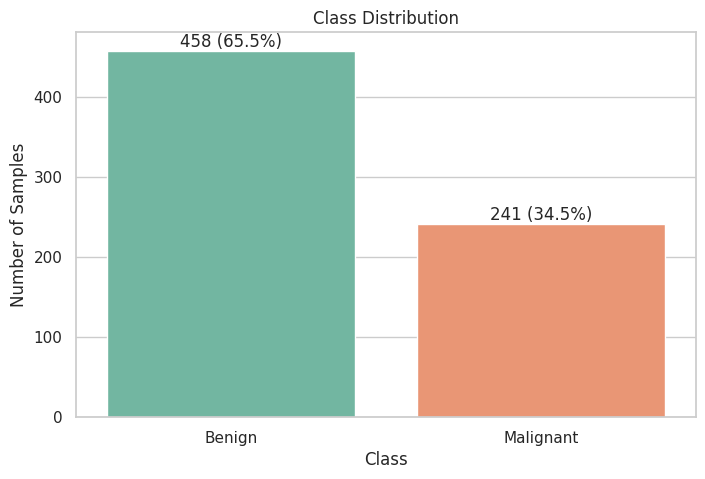

In [ ]:
class_names = {2: "Benign", 4: "Malignant"}

class_counts = data[target_col].value_counts().sort_index()
class_pct = data[target_col].value_counts(normalize=True).sort_index() * 100

class_table = pd.DataFrame({
    "Label": [class_names[c] for c in class_counts.index],
    "Count": class_counts.values,
    "Percent": class_pct.values,
}, index=class_counts.index)
class_table.index.name = "Class"

display(class_table)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Imbalance ratio (majority : minority) = {imbalance_ratio:.2f} : 1")

plt.figure(figsize=(8, 5))
sns.barplot(
    x=class_table["Label"],
    y=class_table["Count"],
    hue=class_table["Label"],
    palette="Set2",
    legend=False
)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

for i, value in enumerate(class_table["Count"]):
    plt.text(i, value, f"{value} ({class_table['Percent'].iloc[i]:.1f}%)",
             ha="center", va="bottom")
plt.show()

# 2) Exploratory Data Analysis (EDA)

The EDA is done on the full raw dataset (before any cleaning or splitting).

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

label_map = {0: "Benign", 1: "Malignant"}
palette = {"Benign": "#2E86AB", "Malignant": "#D1495B"}

# Raw data with readable class labels (NaN still present)
eda_data = data[feature_cols].copy()
eda_data["Class_label"] = data[target_col].map({2: "Benign", 4: "Malignant"})

def pretty(name):
    return name.replace("_", " ")

### 2.1 Distribution of Each Feature

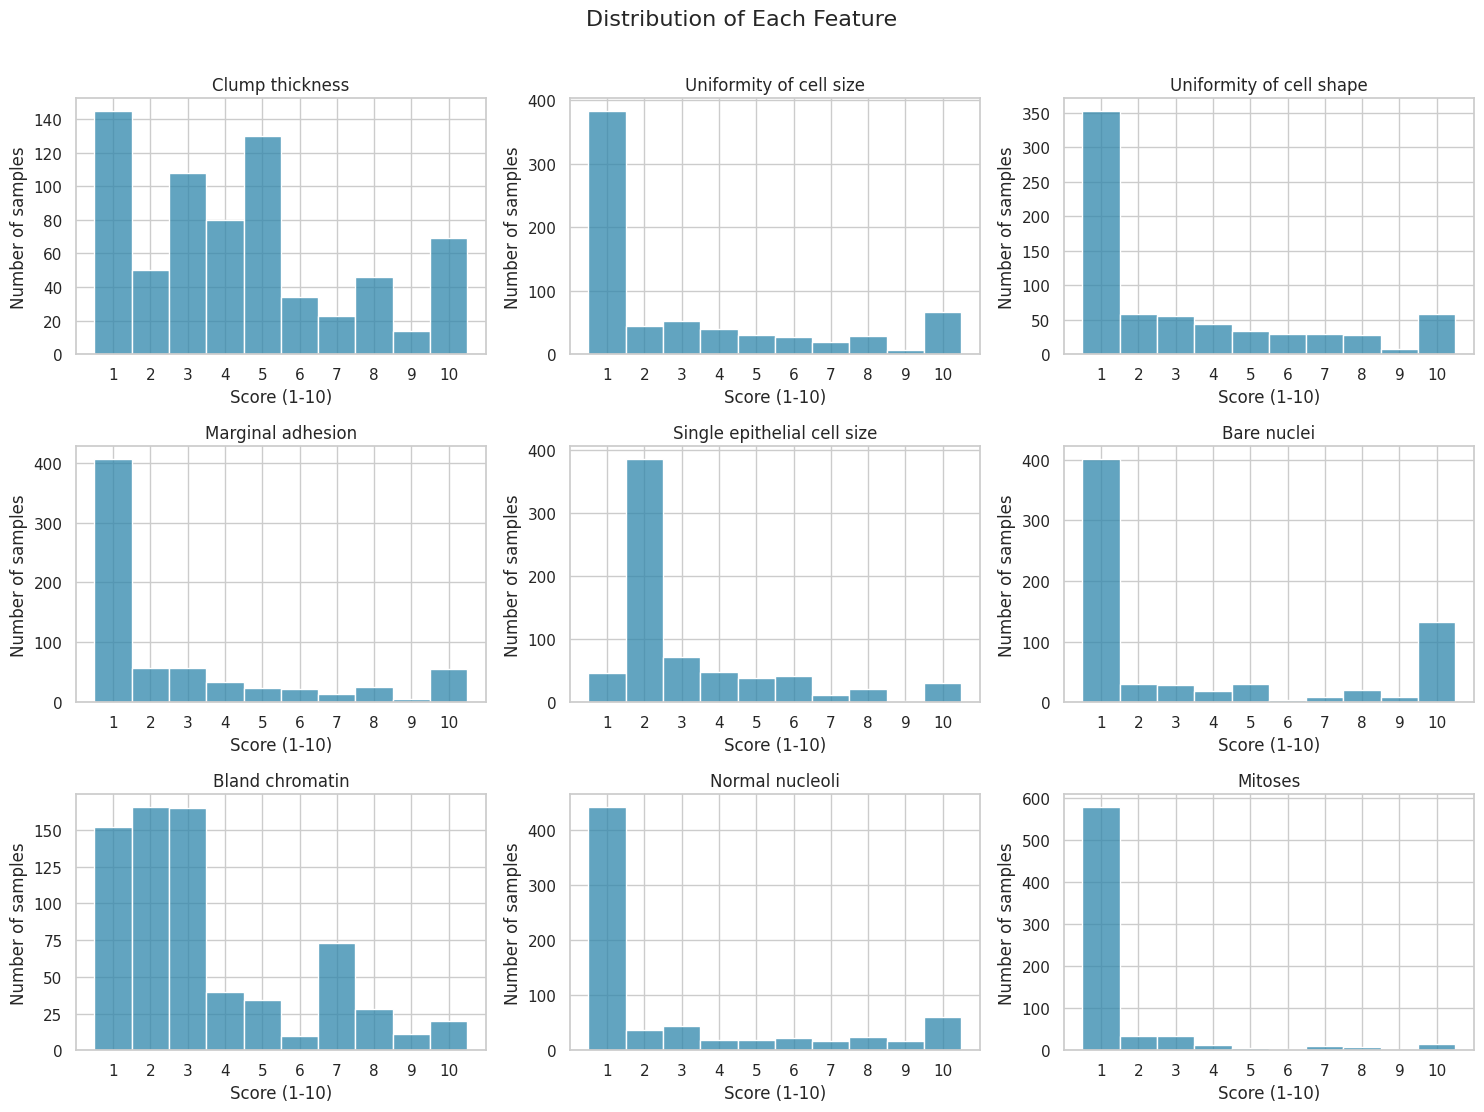

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, col in zip(axes.ravel(), feature_cols):
    sns.histplot(data=eda_data, x=col, discrete=True, color="#2E86AB", edgecolor="white", ax=ax)
    ax.set_title(pretty(col))
    ax.set_xlabel("Score (1-10)")
    ax.set_ylabel("Number of samples")
    ax.set_xticks(range(1, 11))

fig.suptitle("Distribution of Each Feature", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### 2.2 Feature Distributions by Tumor Class

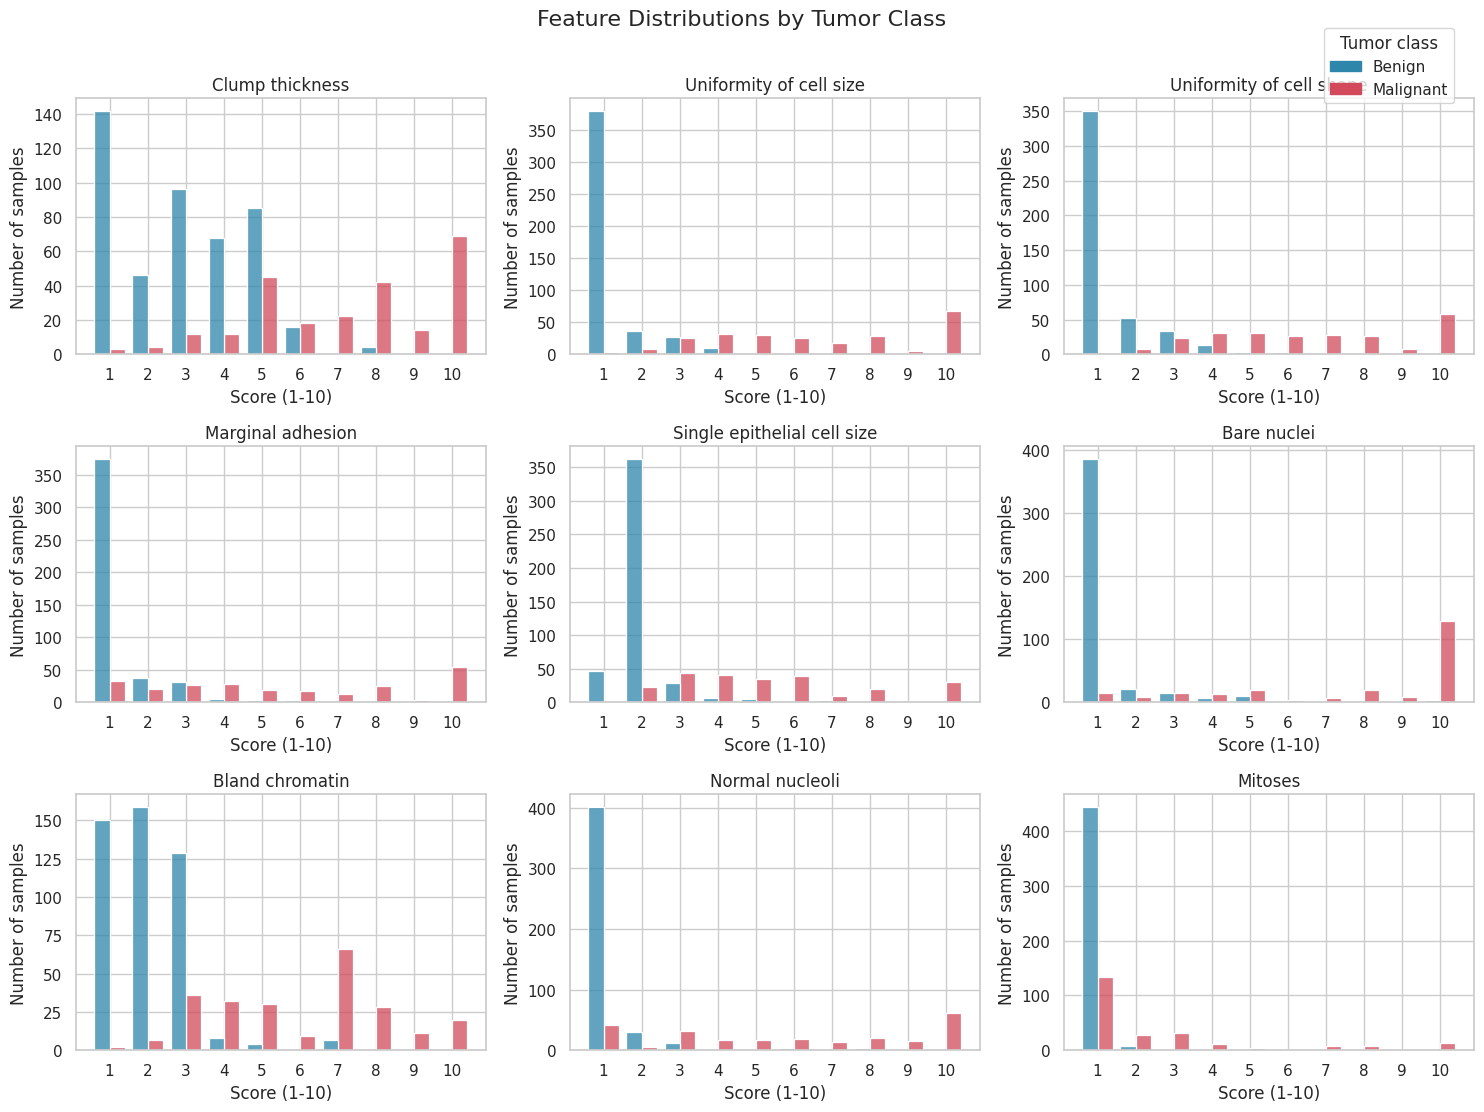

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, col in zip(axes.ravel(), feature_cols):
    sns.histplot(data=eda_data, x=col, hue="Class_label", hue_order=["Benign", "Malignant"],
                 palette=palette, discrete=True, multiple="dodge", shrink=0.8,
                 legend=False, ax=ax)
    ax.set_title(pretty(col))
    ax.set_xlabel("Score (1-10)")
    ax.set_ylabel("Number of samples")
    ax.set_xticks(range(1, 11))

handles = [Patch(color=palette[k], label=k) for k in ["Benign", "Malignant"]]
fig.legend(handles=handles, loc="upper right", title="Tumor class", bbox_to_anchor=(0.98, 1.0))
fig.suptitle("Feature Distributions by Tumor Class", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### 2.3 Correlation Between Features

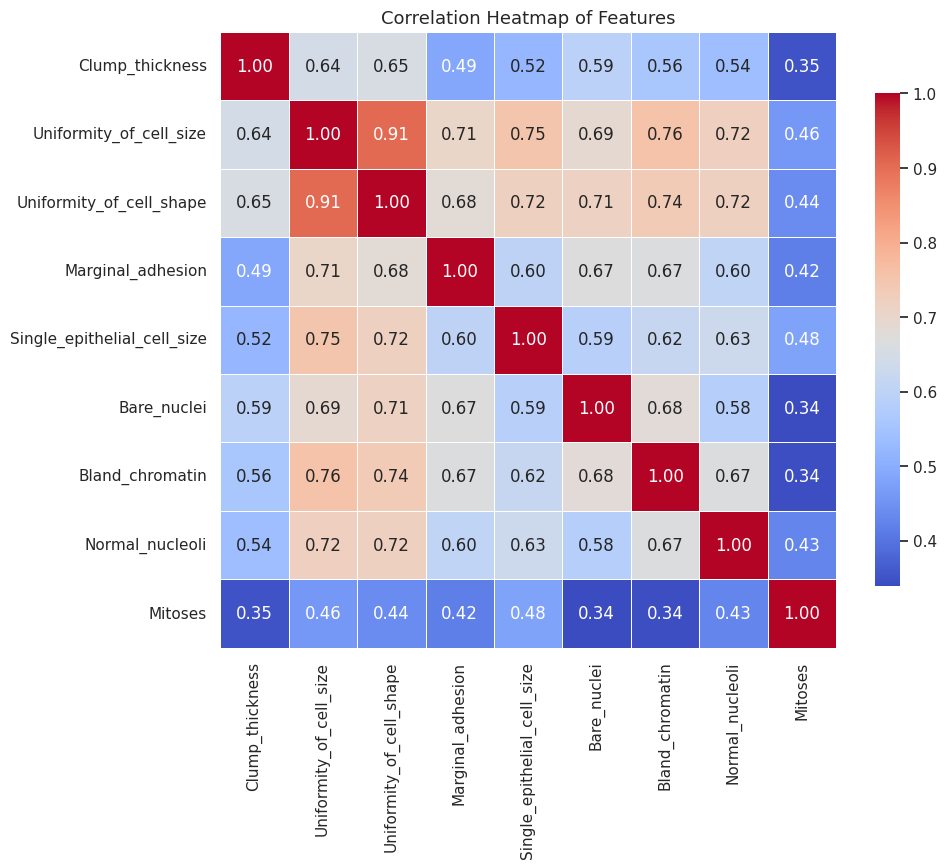

In [ ]:
plt.figure(figsize=(10, 8))
corr = eda_data[feature_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            square=True, linewidths=0.5, cbar_kws={"shrink": .8})
plt.title("Correlation Heatmap of Features", fontsize=13)
plt.show()

### 2.4 Boxplots of All Features

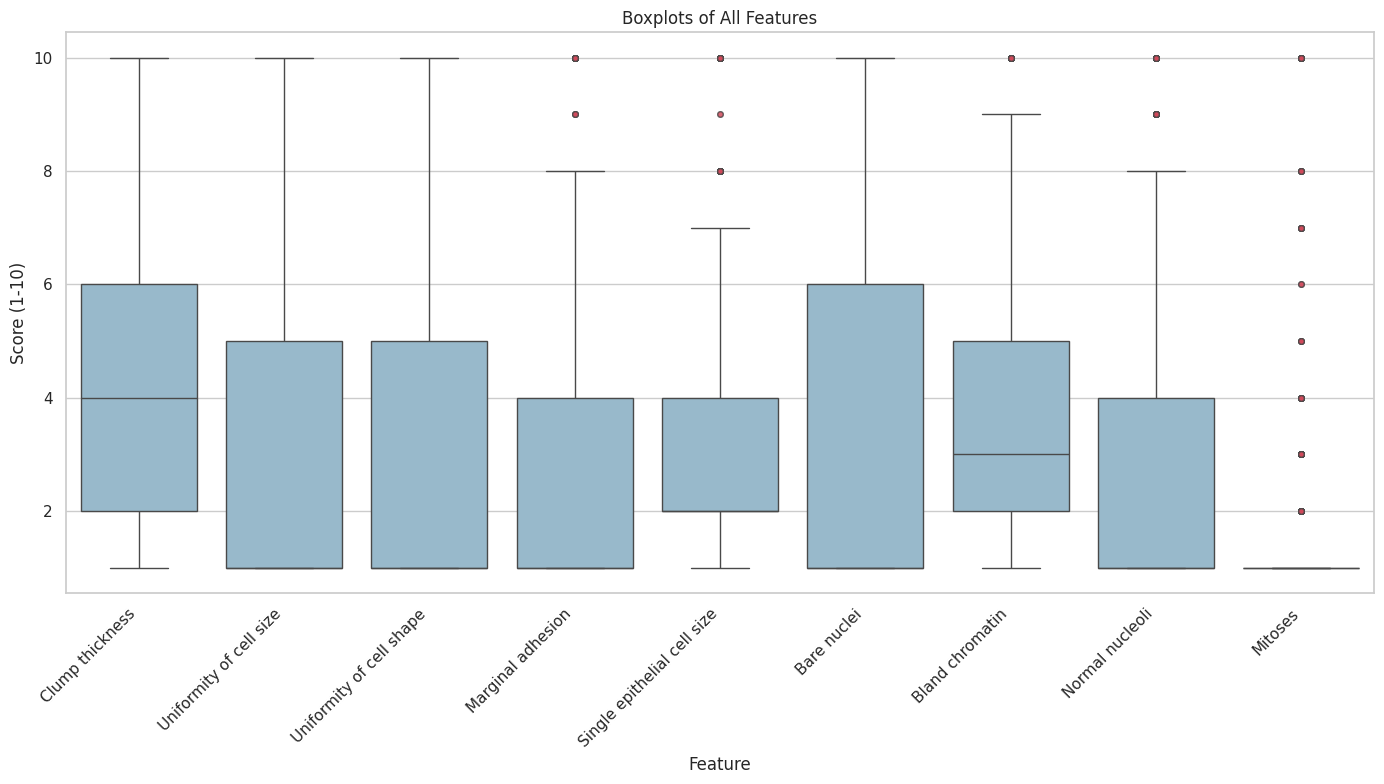

In [ ]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=eda_data[feature_cols].rename(columns=pretty),
    orient="v",
    color="#8FBCD4",
    flierprops=dict(
        marker="o",
        markerfacecolor="#D1495B",
        markersize=4,
        alpha=0.6
    )
)
plt.title("Boxplots of All Features")
plt.xlabel("Feature")
plt.ylabel("Score (1-10)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 2.5 Outlier Count (IQR Rule)

In [ ]:
rows = []
for col in feature_cols:
    q1, q3 = eda_data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((eda_data[col] < lower) | (eda_data[col] > upper)).sum())
    rows.append({"Feature": col, "Q1": q1, "Q3": q3, "Lower_fence": lower,
                 "Upper_fence": upper, "Outliers": n_out,
                 "Outlier_percent": n_out / eda_data[col].notna().sum() * 100})

outlier_table = pd.DataFrame(rows).set_index("Feature")
display(outlier_table)

,Q1,Q3,Lower_fence,Upper_fence,Outliers,Outlier_percent
Feature,,,,,,
Clump_thickness,2.0,6.0,-4.0,12.0,0,0.000000
Uniformity_of_cell_size,1.0,5.0,-5.0,11.0,0,0.000000
Uniformity_of_cell_shape,1.0,5.0,-5.0,11.0,0,0.000000
Marginal_adhesion,1.0,4.0,-3.5,8.5,60,8.583691
Single_epithelial_cell_size,2.0,4.0,-1.0,7.0,54,7.725322
Bare_nuclei,1.0,6.0,-6.5,13.5,0,0.000000
Bland_chromatin,2.0,5.0,-2.5,9.5,20,2.861230
Normal_nucleoli,1.0,4.0,-3.5,8.5,77,11.015737
Mitoses,1.0,1.0,1.0,1.0,120,17.167382


### 2.6 Boxplots by Tumor Class

In [ ]:
# fig, axes = plt.subplots(3, 3, figsize=(14, 12))

# for ax, col in zip(axes.ravel(), feature_cols):
#     sns.boxplot(data=eda_data, x="Class_label", y=col, order=["Benign", "Malignant"],
#                 hue="Class_label", palette=palette, legend=False, ax=ax)
#     ax.set_title(pretty(col))
#     ax.set_xlabel("Tumor class")
#     ax.set_ylabel("Score (1-10)")

# fig.suptitle("Feature Distributions by Tumor Class (Boxplots)", fontsize=16, y=1.01)
# plt.tight_layout()
# plt.show()

# 3) Data Preprocessing

### 3.1 Remove Duplicates

In [ ]:
rows_before = len(data)
data_clean = data.drop_duplicates().reset_index(drop=True)
rows_after = len(data_clean)

print(f"Rows before removing duplicates: {rows_before}")
print(f"Rows after removing duplicates : {rows_after}")
print(f"Rows removed                   : {rows_before - rows_after}")
print(f"Remaining fully duplicated rows: {data_clean.duplicated().sum()}")

Rows before removing duplicates: 699
Rows after removing duplicates : 691
Rows removed                   : 8
Remaining fully duplicated rows: 0


### 3.2 Features, Target, Groups

In [ ]:
X = data_clean[feature_cols].copy()
y = (data_clean[target_col] == 4).astype(int)
groups = data_clean[id_col]

print("Columns used as features:")
print(list(X.columns))
print("\nTarget distribution after recoding (0 = benign, 1 = malignant):")
print(y.value_counts().sort_index())

Columns used as features:
['Clump_thickness', 'Uniformity_of_cell_size', 'Uniformity_of_cell_shape', 'Marginal_adhesion', 'Single_epithelial_cell_size', 'Bare_nuclei', 'Bland_chromatin', 'Normal_nucleoli', 'Mitoses']

Target distribution after recoding (0 = benign, 1 = malignant):
Class
0    453
1    238
Name: count, dtype: int64


### 3.3 Train-Test Split

In [ ]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

n_total = len(X)
print(f"Training set: {X_train.shape}  ({len(X_train) / n_total * 100:.1f}%)")
print(f"Testing set : {X_test.shape}  ({len(X_test) / n_total * 100:.1f}%)")

print("\nMalignant proportion:")
print(f"  Full data : {y.mean() * 100:.1f}%")
print(f"  Train     : {y_train.mean() * 100:.1f}%")
print(f"  Test      : {y_test.mean() * 100:.1f}%")

overlap = set(groups_train) & set(groups_test)
print(f"\nSample IDs shared between train and test: {len(overlap)}")
assert len(overlap) == 0, "Leakage: some sample IDs appear in both sets"

Training set: (557, 9)  (80.6%)
Testing set : (134, 9)  (19.4%)

Malignant proportion:
  Full data : 34.4%
  Train     : 33.4%
  Test      : 38.8%

Sample IDs shared between train and test: 0


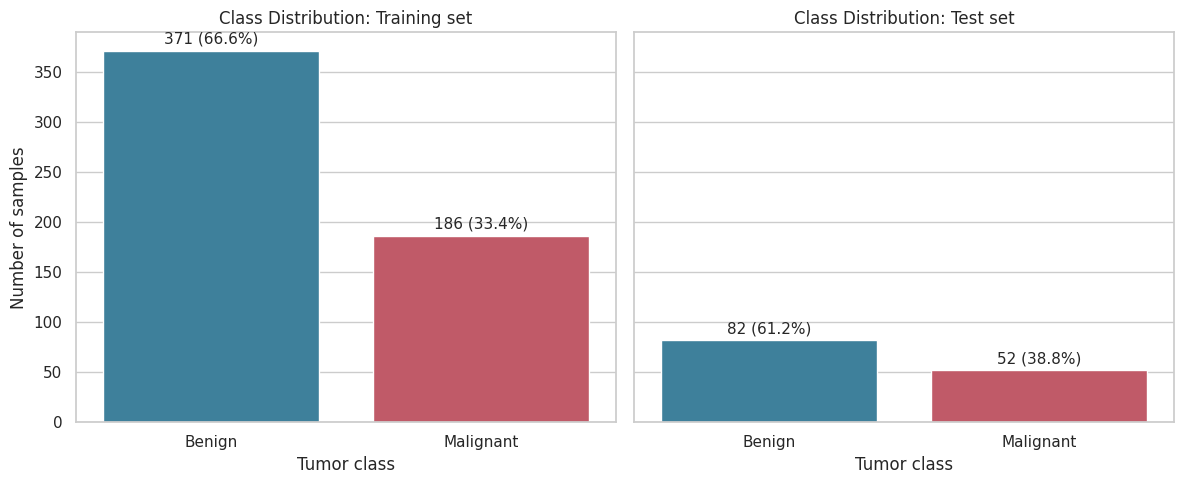

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (name, target_series) in zip(axes, [("Training set", y_train), ("Test set", y_test)]):
    plot_df = pd.DataFrame({"Class": target_series.map(label_map)})
    sns.countplot(data=plot_df, x="Class", order=["Benign", "Malignant"],
                  hue="Class", palette=palette, legend=False, ax=ax)
    total = len(plot_df)
    for patch in ax.patches:
        count = int(patch.get_height())
        ax.annotate(f"{count} ({count / total * 100:.1f}%)",
                    (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                    ha="center", va="bottom", fontsize=11, xytext=(0, 3), textcoords="offset points")
    ax.set_title(f"Class Distribution: {name}")
    ax.set_xlabel("Tumor class")
    ax.set_ylabel("Number of samples")

plt.tight_layout()
plt.show()

### 3.4 Missing Values (Imputation)

In [ ]:
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)   # statistics learned from the training data only

X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=X.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

print("Median values learned from the training set:")
print(pd.Series(imputer.statistics_, index=X.columns))

print("\nMissing values BEFORE imputation (train / test):",
      int(X_train.isnull().sum().sum()), "/", int(X_test.isnull().sum().sum()))
print("Missing values AFTER  imputation (train / test):",
      int(X_train_imp.isnull().sum().sum()), "/", int(X_test_imp.isnull().sum().sum()))

Median values learned from the training set:
Clump_thickness                4.0
Uniformity_of_cell_size        1.0
Uniformity_of_cell_shape       1.0
Marginal_adhesion              1.0
Single_epithelial_cell_size    2.0
Bare_nuclei                    1.0
Bland_chromatin                3.0
Normal_nucleoli                1.0
Mitoses                        1.0
dtype: float64

Missing values BEFORE imputation (train / test): 16 / 0
Missing values AFTER  imputation (train / test): 0 / 0


### 3.5 Feature Standardization

In [ ]:
scaler = StandardScaler()
scaler.fit(X_train_imp)   # mean and std learned from the training data only

X_train_scaled = pd.DataFrame(scaler.transform(X_train_imp), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imp), columns=X.columns, index=X_test.index)

Scaled = pd.DataFrame({
    "Train_mean": X_train_scaled.mean(),
    "Train_std": X_train_scaled.std(ddof=0),
    "Test_mean": X_test_scaled.mean(),
    "Test_std": X_test_scaled.std(ddof=0),
})
display(Scaled)

,Train_mean,Train_std,Test_mean,Test_std
Clump_thickness,8.929621e-17,1.0,0.141918,1.032557
Uniformity_of_cell_size,5.102641e-17,1.0,0.107929,1.121406
Uniformity_of_cell_shape,0.000000e+00,1.0,0.124820,1.099863
Marginal_adhesion,1.148094e-16,1.0,0.056801,1.030819
Single_epithelial_cell_size,-3.826981e-17,1.0,0.080931,1.136192
Bare_nuclei,3.826981e-17,1.0,0.061440,1.033929
Bland_chromatin,-7.653961e-17,1.0,0.043907,0.974671
Normal_nucleoli,-6.378301e-17,1.0,0.101466,1.127383
Mitoses,-1.275660e-17,1.0,0.137086,1.190146


### 3.6 Pipeline and Cross Validation

In [ ]:
def make_preprocessor():
    """Return a fresh imputation + scaling pipeline (fit separately inside each CV fold)."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

# Cross-validation strategy used for all tuning: stratified and grouped by sample ID
cv_strategy = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Quick check that the pipeline works on the training data
check = make_preprocessor().fit(X_train)
print("Pipeline output shape on training data:", check.transform(X_train).shape)

Pipeline output shape on training data: (557, 9)


### 3.7 Correlation After Preprocessing

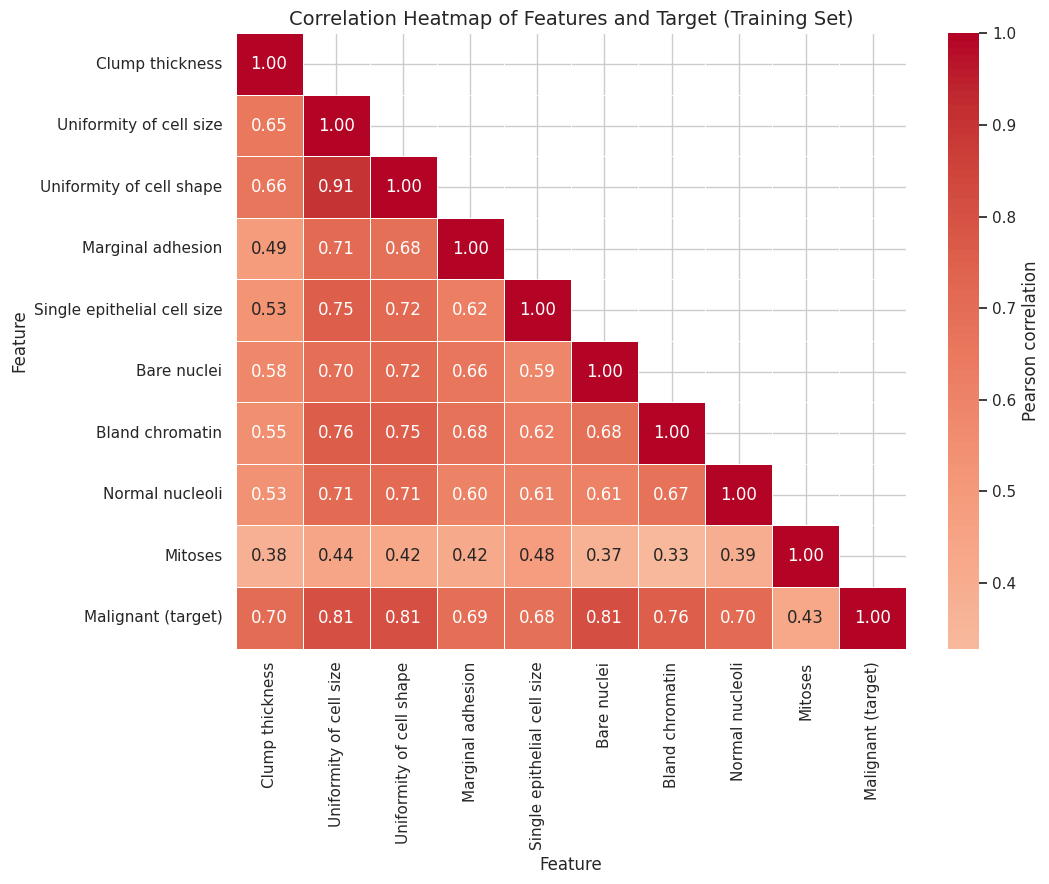

In [ ]:
corr_df = X_train_imp.copy()
corr_df["Malignant (target)"] = y_train
corr = corr_df.corr()

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(11, 9))
sns.heatmap(corr.rename(index=pretty, columns=pretty), mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Features and Target (Training Set)", fontsize=14)
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
print("Correlation of each feature with the target (malignant = 1):")
print(corr["Malignant (target)"].drop("Malignant (target)").sort_values(ascending=False).round(3))

feat_corr = corr.loc[feature_cols, feature_cols]
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool)).stack()
print("\nHighly correlated feature pairs (|r| > 0.70):")
print(upper[upper.abs() > 0.70].sort_values(ascending=False).round(3))

Correlation of each feature with the target (malignant = 1):
Bare_nuclei                    0.814
Uniformity_of_cell_size        0.811
Uniformity_of_cell_shape       0.811
Bland_chromatin                0.757
Normal_nucleoli                0.704
Clump_thickness                0.701
Marginal_adhesion              0.695
Single_epithelial_cell_size    0.680
Mitoses                        0.428
Name: Malignant (target), dtype: float64

Highly correlated feature pairs (|r| > 0.70):
Uniformity_of_cell_size   Uniformity_of_cell_shape       0.905
                          Bland_chromatin                0.763
                          Single_epithelial_cell_size    0.754
Uniformity_of_cell_shape  Bland_chromatin                0.752
                          Bare_nuclei                    0.719
                          Single_epithelial_cell_size    0.718
                          Normal_nucleoli                0.711
Uniformity_of_cell_size   Normal_nucleoli                0.707
              

### 3.8 Before vs. After Standardization

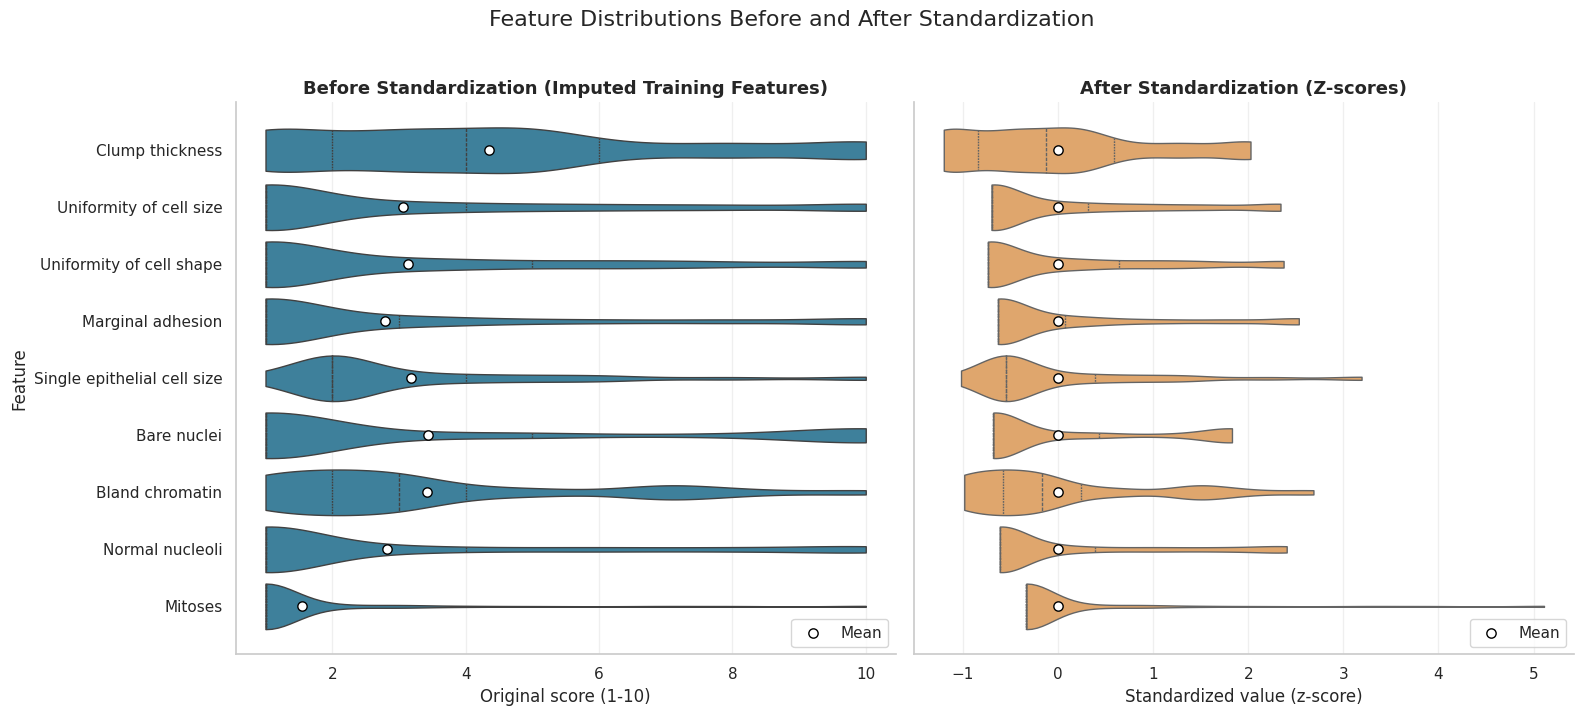

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

panels = [
    (X_train_imp, "Before Standardization (Imputed Training Features)", "Original score (1-10)", "#2E86AB"),
    (X_train_scaled, "After Standardization (Z-scores)", "Standardized value (z-score)", "#F2A65A"),
]

for ax, (df, title, xlabel, color) in zip(axes, panels):
    df = df.rename(columns=pretty)
    long_df = df.melt(var_name="Feature", value_name="Value")

    # Violin = full distribution shape, inner lines = quartiles (25%, median, 75%)
    sns.violinplot(data=long_df, x="Value", y="Feature", orient="h",
                   color=color, inner="quartile", cut=0, linewidth=1,
                   density_norm="width", ax=ax)

    # Mean of each feature
    ax.scatter(df.mean().values, range(df.shape[1]), s=45, color="white",
               edgecolor="black", zorder=5, label="Mean")

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Feature" if ax is axes[0] else "")
    ax.grid(axis="x", alpha=0.3)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right", frameon=True)

fig.suptitle("Feature Distributions Before and After Standardization", fontsize=16, y=1.02)
sns.despine()
plt.tight_layout()
plt.show()

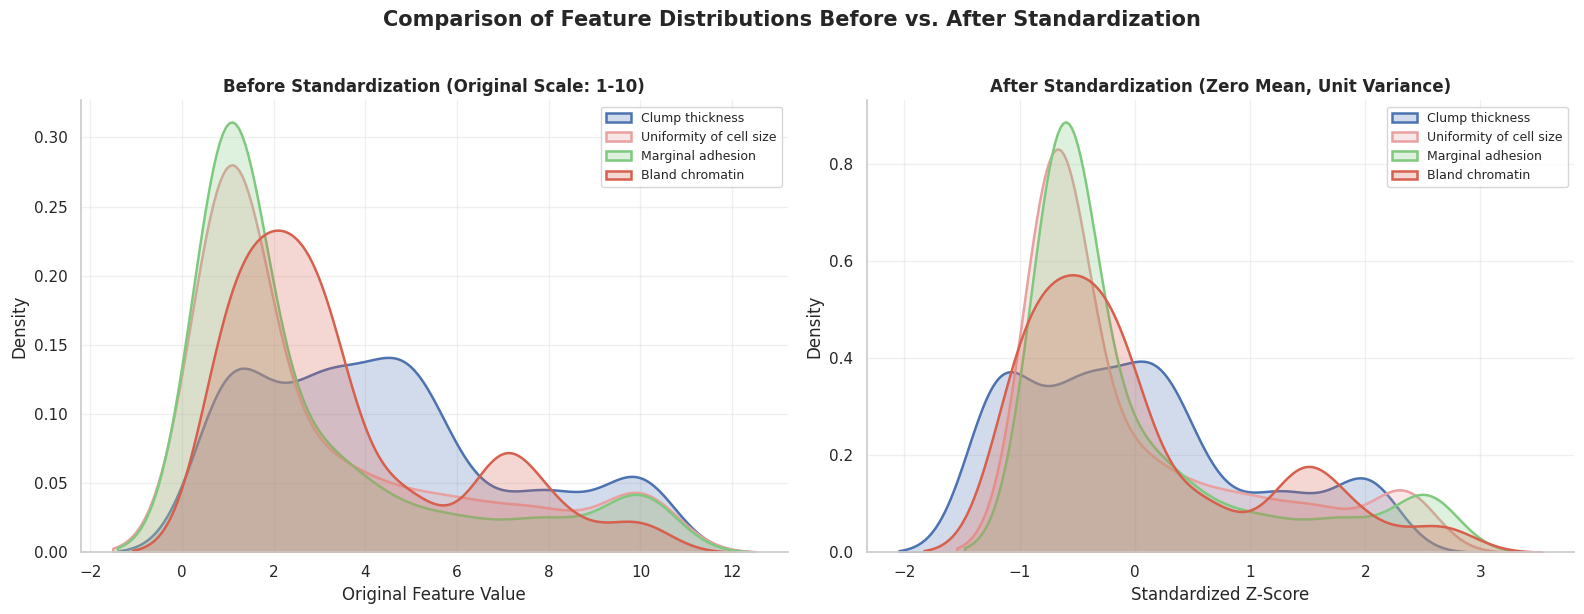

In [ ]:
selected = ["Clump_thickness", "Uniformity_of_cell_size", "Marginal_adhesion", "Bland_chromatin"]
colors = ["#4C72B0", "#E8A0A0", "#7FC97F", "#D6604D"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

panels = [
    (X_train_imp, "Before Standardization (Original Scale: 1-10)", "Original Feature Value", "Density"),
    (X_train_scaled, "After Standardization (Zero Mean, Unit Variance)", "Standardized Z-Score", "Density"),
]

for ax, (df, title, xlabel, ylabel) in zip(axes, panels):
    for col, color in zip(selected, colors):
        sns.kdeplot(df[col], fill=True, alpha=0.25, linewidth=1.8,
                    color=color, label=pretty(col), ax=ax)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc="upper right", fontsize=9, frameon=True)
    ax.grid(alpha=0.3)

fig.suptitle("Comparison of Feature Distributions Before vs. After Standardization",
             fontsize=15, fontweight="bold", y=1.02)
sns.despine()
plt.tight_layout()
plt.show()

# 4) Model Implementation & Evaluation

### Setup: Scoring, Search Helper, and Evaluation Helpers

In [ ]:
# Malignant (label 1) is the positive class for every metric
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}

def select_best(cv_results):
    """Refit rule: choose the candidate with the highest mean CV F1-score."""
    return int(np.argmax(cv_results["mean_test_f1"]))

def make_pipeline(classifier):
    """Preprocessing (imputation + scaling) followed by the classifier."""
    return Pipeline([
        ("prep", make_preprocessor()),
        ("clf", classifier),
    ])

searches = {}
best_models = {}
summary_rows = []

def run_search(name, classifier, param_space, search_type="grid", n_iter=50):
    pipe = make_pipeline(classifier)
    common = dict(scoring=scoring, refit=select_best, cv=cv_strategy, n_jobs=-1, verbose=0)

    if search_type == "grid":
        search = GridSearchCV(pipe, param_space, **common)
    else:
        search = RandomizedSearchCV(pipe, param_space, n_iter=n_iter,
                                    random_state=RANDOM_STATE, **common)

    search.fit(X_train, y_train, groups=groups_train)

    idx = search.best_index_
    res = search.cv_results_
    row = {"Model": name}
    for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        row[f"CV_{m}"] = res[f"mean_test_{m}"][idx]
        row[f"CV_{m}_std"] = res[f"std_test_{m}"][idx]
    row["Candidates_tested"] = len(res["params"])
    row["Best_params"] = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}

    searches[name] = search
    best_models[name] = search.best_estimator_
    summary_rows.append(row)

    print(f"{name}")
    print(f"  Candidates tested : {row['Candidates_tested']} x 5 folds")
    print(f"  Best parameters   : {row['Best_params']}")
    print(f"  CV accuracy  = {row['CV_accuracy']:.4f} (+/- {row['CV_accuracy_std']:.4f})")
    print(f"  CV precision = {row['CV_precision']:.4f}")
    print(f"  CV recall    = {row['CV_recall']:.4f}")
    print(f"  CV F1-score  = {row['CV_f1']:.4f}")
    print(f"  CV ROC-AUC   = {row['CV_roc_auc']:.4f}")
    return search

def get_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def plot_confusion_matrix(name):
    """Confusion matrix of a tuned model on the test set."""
    model = best_models[name]
    y_pred = model.predict(X_test)
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["Benign", "Malignant"],
        cmap="Blues", colorbar=False, ax=ax, values_format="d")
    ax.set_title(f"Confusion Matrix: {name} (Test Set)")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.grid(False)
    plt.tight_layout()
    plt.show()

### 4.1 K-Nearest Neighbors (KNN)

In [ ]:
knn_space = {
    "clf__n_neighbors": list(range(1, 32, 2)),
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "manhattan"],
}

run_search("KNN", KNeighborsClassifier(), knn_space, search_type="grid")

KNN
  Candidates tested : 64 x 5 folds
  Best parameters   : {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'distance'}
  CV accuracy  = 0.9642 (+/- 0.0168)
  CV precision = 0.9465
  CV recall    = 0.9468
  CV F1-score  = 0.9466
  CV ROC-AUC   = 0.9888


GridSearchCV(cv=StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('prep',
                                        Pipeline(steps=[('imputer',
                                                         SimpleImputer(strategy='median')),
                                                        ('scaler',
                                                         StandardScaler())])),
                                       ('clf', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'clf__metric': ['euclidean', 'manhattan'],
                         'clf__n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19,
                                              21, 23, 25, 27, 29, 31],
                         'clf__weights': ['uniform', 'distance']},
             refit=<function select_best at 0x7bb1473eb1a0>,
             scoring={'accuracy': 'accuracy',
                      'f1': make_scorer(f1_score, response_method='predict', zero_division=0),
                      'precision': make_scorer(precision_score, response_method='predict', zero_division=0),
                      'recall': 'recall', 'roc_auc': 'roc_auc'})

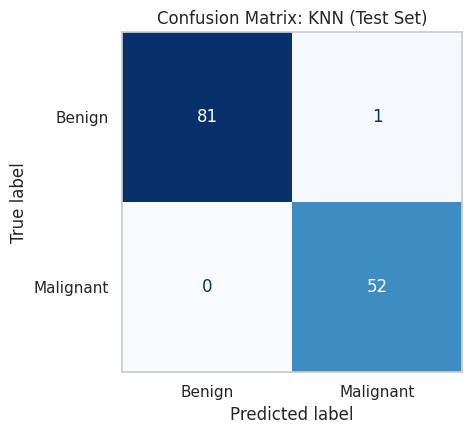

In [ ]:
plot_confusion_matrix("KNN")

### 4.2 Decision Tree

In [ ]:
dt_space = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "clf__min_samples_split": [2, 5, 10, 20],
    "clf__min_samples_leaf": [1, 2, 4, 8],
    "clf__class_weight": [None, "balanced"],
}

run_search("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE),
           dt_space, search_type="grid")

Decision Tree
  Candidates tested : 512 x 5 folds
  Best parameters   : {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 2}
  CV accuracy  = 0.9460 (+/- 0.0130)
  CV precision = 0.8805
  CV recall    = 0.9676
  CV F1-score  = 0.9217
  CV ROC-AUC   = 0.9651


GridSearchCV(cv=StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('prep',
                                        Pipeline(steps=[('imputer',
                                                         SimpleImputer(strategy='median')),
                                                        ('scaler',
                                                         StandardScaler())])),
                                       ('clf',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'clf__class_weight': [None, 'balanced'],
                         'clf__criterion': ['gini', 'entropy'],
                         'clf__max_depth': [2, 3, 4, 5, 6, 8, 10, None],
                         'clf__min_samples_leaf': [1, 2, 4, 8],
                         'clf__min_samples_split': [2, 5, 10, 20]},
             refit=<function select_best at 0x7bb1473eb1a0>,
             scoring={'accuracy': 'accuracy',
                      'f1': make_scorer(f1_score, response_method='predict', zero_division=0),
                      'precision': make_scorer(precision_score, response_method='predict', zero_division=0),
                      'recall': 'recall', 'roc_auc': 'roc_auc'})

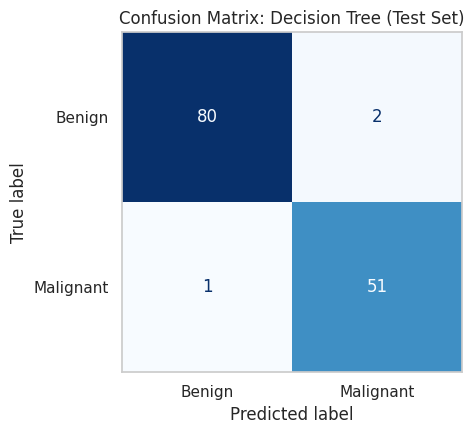

In [ ]:
plot_confusion_matrix("Decision Tree")

### 4.3 Random Forest

In [ ]:
rf_space = {
    "clf__n_estimators": [100, 200, 300, 500],
    "clf__max_depth": [None, 4, 6, 8, 10],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2", None],
    "clf__class_weight": [None, "balanced"],
}

run_search("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
           rf_space, search_type="random", n_iter=60)

Random Forest
  Candidates tested : 60 x 5 folds
  Best parameters   : {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None, 'class_weight': None}
  CV accuracy  = 0.9695 (+/- 0.0133)
  CV precision = 0.9436
  CV recall    = 0.9676
  CV F1-score  = 0.9553
  CV ROC-AUC   = 0.9891


RandomizedSearchCV(cv=StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('prep',
                                              Pipeline(steps=[('imputer',
                                                               SimpleImputer(strategy='median')),
                                                              ('scaler',
                                                               StandardScaler())])),
                                             ('clf',
                                              RandomForestClassifier(n_jobs=1,
                                                                     random_state=42))]),
                   n_iter=60, n_jobs=-1,
                   param_distributions={'clf__class_weight': [None, 'balanced'],
                                        'c...
                                        'clf__min_samples_split': [2, 5, 10],
                                        'clf__n_estimators': [100, 200, 300,
                                                              500]},
                   random_state=42,
                   refit=<function select_best at 0x7bb1473eb1a0>,
                   scoring={'accuracy': 'accuracy',
                            'f1': make_scorer(f1_score, response_method='predict', zero_division=0),
                            'precision': make_scorer(precision_score, response_method='predict', zero_division=0),
                            'recall': 'recall', 'roc_auc': 'roc_auc'})

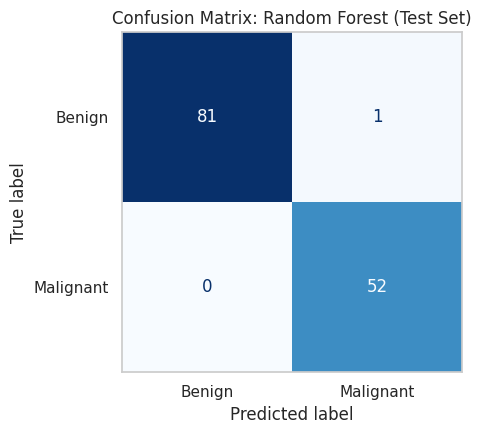

In [ ]:
plot_confusion_matrix("Random Forest")

### 4.4 Support Vector Machine (SVM)

In [ ]:
svm_space = [
    {   # RBF kernel
        "clf__kernel": ["rbf"],
        "clf__C": [0.1, 1, 10, 100],
        "clf__gamma": ["scale", 0.001, 0.01, 0.1, 1],
        "clf__class_weight": [None, "balanced"],
    },
    {   # Linear kernel
        "clf__kernel": ["linear"],
        "clf__C": [0.01, 0.1, 1, 10, 100],
        "clf__class_weight": [None, "balanced"],
    },
    {   # Polynomial kernel
        "clf__kernel": ["poly"],
        "clf__C": [0.1, 1, 10],
        "clf__degree": [2, 3],
        "clf__gamma": ["scale"],
        "clf__class_weight": [None, "balanced"],
    },
]

run_search("SVM", SVC(random_state=RANDOM_STATE), svm_space, search_type="grid")

SVM
  Candidates tested : 62 x 5 folds
  Best parameters   : {'C': 100, 'class_weight': None, 'gamma': 0.001, 'kernel': 'rbf'}
  CV accuracy  = 0.9641 (+/- 0.0178)
  CV precision = 0.9423
  CV recall    = 0.9510
  CV F1-score  = 0.9465
  CV ROC-AUC   = 0.9931


GridSearchCV(cv=StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('prep',
                                        Pipeline(steps=[('imputer',
                                                         SimpleImputer(strategy='median')),
                                                        ('scaler',
                                                         StandardScaler())])),
                                       ('clf', SVC(random_state=42))]),
             n_jobs=-1,
             param_grid=[{'clf__C': [0.1, 1, 10, 100],
                          'clf__class_weight': [None, 'balanced'],
                          'clf__gamma': ['scale', 0.001, 0....
                          'clf__class_weight': [None, 'balanced'],
                          'clf__degree': [2, 3], 'clf__gamma': ['scale'],
                          'clf__kernel': ['poly']}],
             refit=<function select_best at 0x7bb1473eb1a0>,
             scoring={'accuracy': 'accuracy',
                      'f1': make_scorer(f1_score, response_method='predict', zero_division=0),
                      'precision': make_scorer(precision_score, response_method='predict', zero_division=0),
                      'recall': 'recall', 'roc_auc': 'roc_auc'})

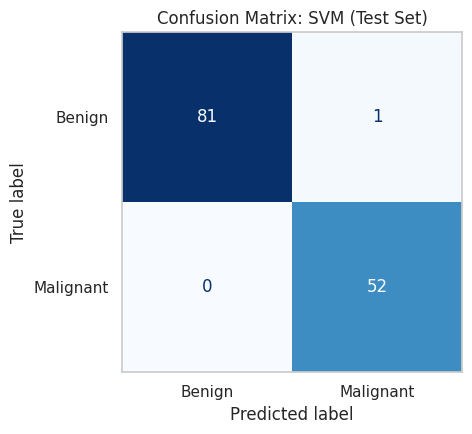

In [ ]:
plot_confusion_matrix("SVM")

### 4.5 Artificial Neural Network (MLP)

In [ ]:
ann_space = {
    "clf__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (16, 8), (32, 16), (64, 32)],
    "clf__activation": ["relu", "tanh"],
    "clf__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1.0],
    "clf__learning_rate_init": [0.001, 0.005, 0.01],
}

run_search("ANN (MLP)",
           MLPClassifier(solver="adam", max_iter=2000, random_state=RANDOM_STATE),
           ann_space, search_type="random", n_iter=40)

ANN (MLP)
  Candidates tested : 40 x 5 folds
  Best parameters   : {'learning_rate_init': 0.001, 'hidden_layer_sizes': (8,), 'alpha': 1.0, 'activation': 'relu'}
  CV accuracy  = 0.9658 (+/- 0.0173)
  CV precision = 0.9336
  CV recall    = 0.9671
  CV F1-score  = 0.9498
  CV ROC-AUC   = 0.9926


RandomizedSearchCV(cv=StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('prep',
                                              Pipeline(steps=[('imputer',
                                                               SimpleImputer(strategy='median')),
                                                              ('scaler',
                                                               StandardScaler())])),
                                             ('clf',
                                              MLPClassifier(max_iter=2000,
                                                            random_state=42))]),
                   n_iter=40, n_jobs=-1,
                   param_distributions={'clf__activation': ['relu', 'tanh'],
                                        'clf__alph...
                                                                    (16, 8),
                                                                    (32, 16),
                                                                    (64, 32)],
                                        'clf__learning_rate_init': [0.001,
                                                                    0.005,
                                                                    0.01]},
                   random_state=42,
                   refit=<function select_best at 0x7bb1473eb1a0>,
                   scoring={'accuracy': 'accuracy',
                            'f1': make_scorer(f1_score, response_method='predict', zero_division=0),
                            'precision': make_scorer(precision_score, response_method='predict', zero_division=0),
                            'recall': 'recall', 'roc_auc': 'roc_auc'})

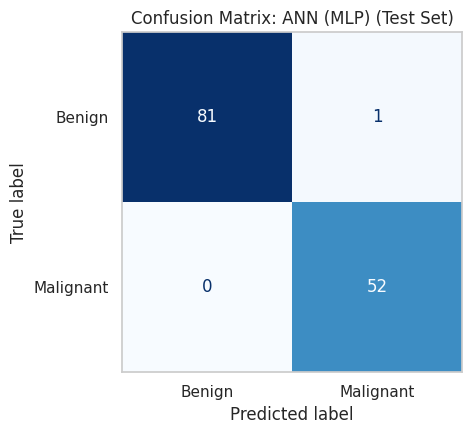

In [ ]:
plot_confusion_matrix("ANN (MLP)")

### 4.6 Model Comparison and Best Model Selection

In [ ]:
# Test-set predictions of every tuned model
predictions = {name: (m.predict(X_test), get_scores(m, X_test)) for name, m in best_models.items()}

rows = []
for name, (y_pred, y_score) in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
    })

comparison = pd.DataFrame(rows).set_index("Model")
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

# Cross-validation F1 from the tuning step (consistency check against the test F1)
comparison["CV F1"] = pd.Series({r["Model"]: r["CV_f1"] for r in summary_rows})

# Overall rank: mean rank over the five metrics, ties broken by FN then FP
comparison["Mean rank"] = comparison[metric_cols].rank(ascending=False, method="min").mean(axis=1)
comparison = comparison.sort_values(["Mean rank", "FN", "FP"])
comparison["Overall rank"] = range(1, len(comparison) + 1)

formats = {c: "{:.4f}" for c in metric_cols + ["CV F1"]}
formats["Mean rank"] = "{:.2f}"

display(comparison.style
        .format(formats)
        .set_caption("Test-set results of all models (positive class = malignant)"))
print(f"Best model by overall rank: {comparison.index[0]}")

,Accuracy,Precision,Recall,F1-score,ROC-AUC,TP,TN,FP,FN,CV F1,Mean rank,Overall rank
Model,,,,,,,,,,,,
ANN (MLP),0.9925,0.9811,1.0000,0.9905,0.9993,52,81,1,0,0.9498,1.00,1
SVM,0.9925,0.9811,1.0000,0.9905,0.9991,52,81,1,0,0.9465,1.20,2
Random Forest,0.9925,0.9811,1.0000,0.9905,0.9988,52,81,1,0,0.9553,1.40,3
KNN,0.9925,0.9811,1.0000,0.9905,0.9960,52,81,1,0,0.9466,1.60,4
Decision Tree,0.9776,0.9623,0.9808,0.9714,0.9894,51,80,2,1,0.9217,5.00,5


Best model by overall rank: ANN (MLP)


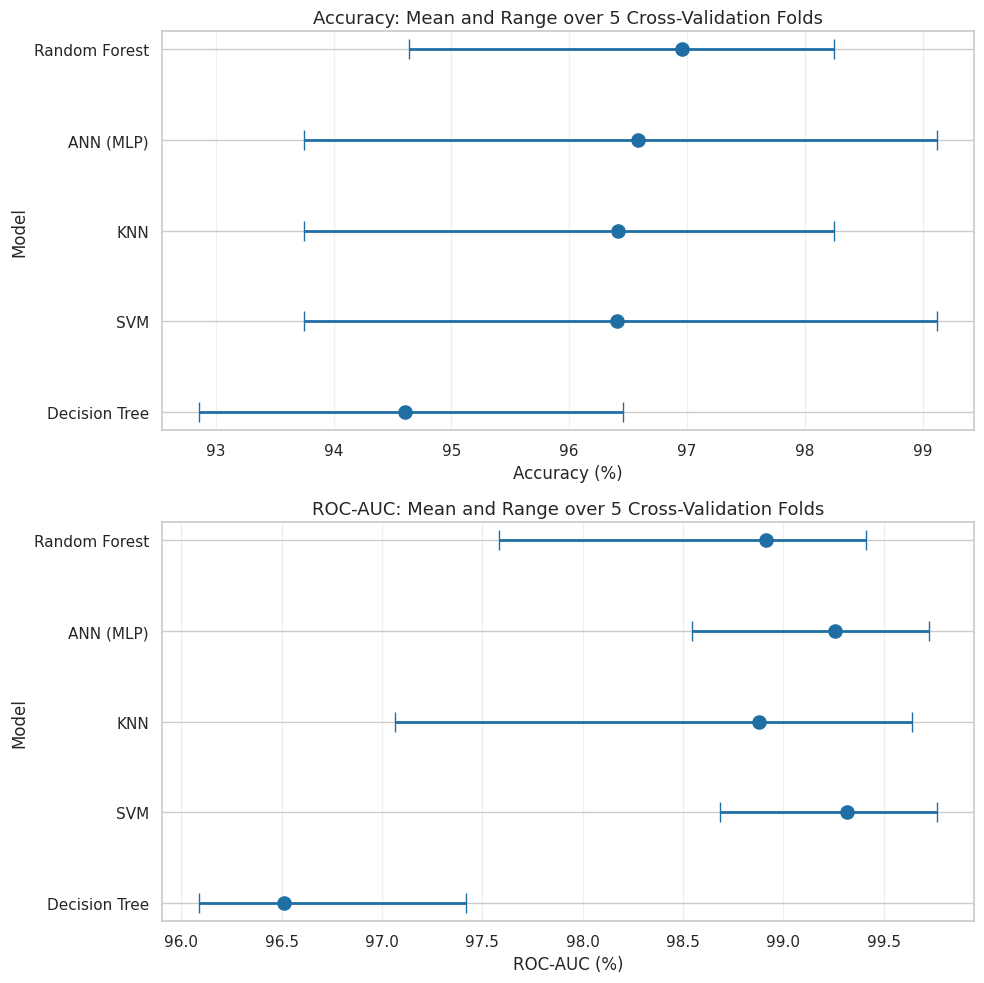

In [ ]:
metrics = ["accuracy", "roc_auc"]
metric_titles = {"accuracy": "Accuracy", "roc_auc": "ROC-AUC"}

# Per-fold scores of the best configuration of each model (5 folds)
fold_scores = {}
for name, search in searches.items():
    idx = search.best_index_
    res = search.cv_results_
    fold_scores[name] = {m: np.array([res[f"split{k}_test_{m}"][idx] for k in range(5)]) * 100
                         for m in metrics}

# Sort models by mean accuracy (best at the top)
order = sorted(fold_scores, key=lambda n: fold_scores[n]["accuracy"].mean(), reverse=True)
ypos = np.arange(len(order))

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

for ax, m in zip(axes, metrics):
    for y_pos, name in zip(ypos, order):
        s = fold_scores[name][m]
        ax.hlines(y_pos, s.min(), s.max(), color="#1F6FA5", linewidth=2)
        ax.plot([s.min(), s.max()], [y_pos, y_pos], linestyle="none", marker="|",
                markersize=14, color="#1F6FA5")
        ax.scatter(s.mean(), y_pos, s=90, color="#1F6FA5", zorder=3)
    ax.set_yticks(ypos)
    ax.set_yticklabels(order)
    ax.invert_yaxis()
    ax.set_title(f"{metric_titles[m]}: Mean and Range over 5 Cross-Validation Folds", fontsize=13)
    ax.set_xlabel(f"{metric_titles[m]} (%)")
    ax.set_ylabel("Model")
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
fig.savefig("cv_accuracy_rocauc_ranges.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.7 Discussion of the Test-Set Results

The five tuned models were evaluated once on the held-out test set (139 samples: 48 malignant and 91 benign). This set was not used for training, preprocessing, or hyperparameter tuning. Malignant is the positive class.

**Key observations:**
- **ANN, SVM and Random Forest** detected every malignant tumor (recall = 1.0000, FN = 0). They differ only in false alarms: ANN raised 2, while SVM and Random Forest raised 3 each.
- **KNN** made 1 false alarm and missed 1 malignant tumor (precision = recall = 0.9792).
- **Decision Tree** was the weakest model (accuracy 0.9496, F1-score 0.9293): it missed 2 malignant tumors and raised 5 false alarms. A single tree makes hard, high-variance splits, which makes it less stable than the other models.

**Best model: ANN (MLP)**
1. Best mean rank over the five metrics (1.20), followed by SVM (2.20), KNN (2.40), Random Forest (2.60) and Decision Tree (5.00).
2. Recall of 1.0000 (no missed malignant tumor), which matters most in medical screening because a false negative is far more costly than a false alarm.
3. Highest test F1-score (0.9796) and the joint-highest accuracy (0.9856, tied with KNN), with only 2 false alarms.
4. Its cross-validation F1-score (0.9535) and ROC-AUC (0.9924) are consistent with the test results.

**Caveats:**
- The top models are practically equivalent: one test sample changes accuracy by about 0.72 percentage points (1 / 139), so the differences between them are within random variation.
- Test F1-scores are higher than the cross-validation F1-scores for most models, so the test results should be read as an optimistic estimate.
- Random Forest had the highest cross-validation F1-score (0.9621) and provides feature importance, so it is a strong alternative when interpretability matters.
- The selected ANN uses a single hidden layer of 8 neurons with `alpha = 1.0`, the upper limit of the searched range, so a wider search range is a natural improvement.
- Exact numbers can change slightly with a different scikit-learn version, so re-check this text after running the notebook.